<a href="https://colab.research.google.com/github/rishinani/Hackathon_T057/blob/main/Ques_45_1571.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install numpy pandas matplotlib scipy scikit-learn torch


In [2]:

!pip install strawberryfields


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 9.3 MB/s  0:00:00
  Created wheel for antlr4-python3-runtime: filename=antlr4_python3_runtime-4.9.2-py3-none-any.whl size=144583 sha256=8d90e51692e410b2b815ee645ca80586767dbe930c1bfe421749ee7ef1b7a0a6
  Stored in directory: /root/.cache/pip/wheels/07/2f/83/742e58040b1da6254ceed430f24125182e1cc74ad37fc45e8b
Successfully built antlr4-python3-runtime
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [strawberryfields]


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.stats import wasserstein_distance

np.random.seed(42)
torch.manual_seed(42)

print("Libraries imported successfully")


Libraries imported successfully


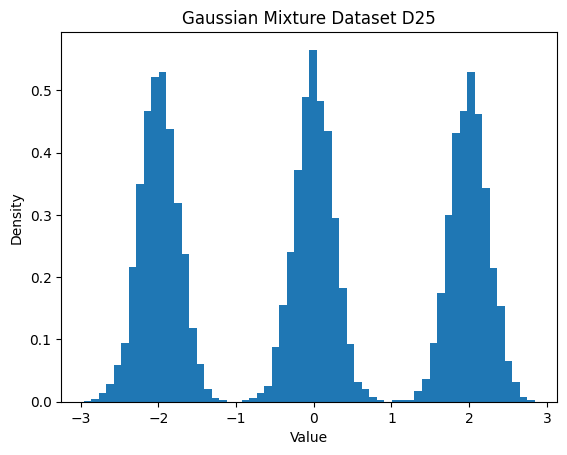

      value
0 -0.371965
1  1.718703
2  2.097205
3 -0.293468
4 -1.721841
Dataset shape: (10000, 1)


In [4]:

n = 10000

centers = [-2, 0, 2]
std = 0.25

components = np.random.choice(
    centers, size=n, p=[1/3, 1/3, 1/3]
)

gaussian_data = np.random.normal(
    components, std
)

df1 = pd.DataFrame({
    "value": gaussian_data
})

df1.to_csv("D25_Gaussian_Mixture.csv", index=False)

plt.hist(gaussian_data, bins=60, density=True)
plt.title("Gaussian Mixture Dataset D25")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()

print(df1.head())
print("Dataset shape:", df1.shape)


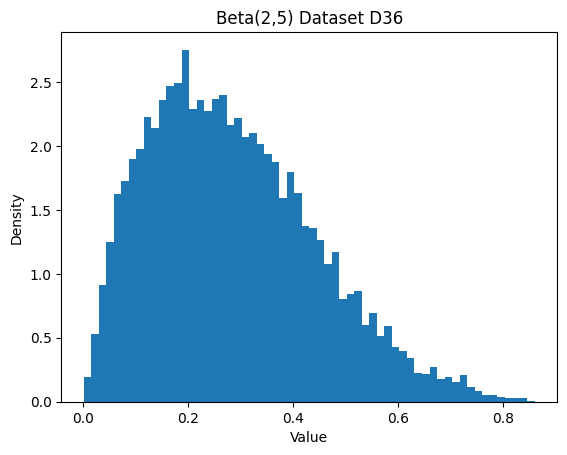

      value
0  0.203929
1  0.316255
2  0.287081
3  0.230782
4  0.531003
Dataset shape: (10000, 1)


In [5]:

beta_data = np.random.beta(2, 5, size=10000)

df2 = pd.DataFrame({
    "value": beta_data
})

df2.to_csv("D36_Beta_2_5.csv", index=False)

plt.hist(beta_data, bins=60, density=True)
plt.title("Beta(2,5) Dataset D36")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()

print(df2.head())
print("Dataset shape:", df2.shape)


In [6]:

from google.colab import files

files.download("D25_Gaussian_Mixture.csv")
files.download("D36_Beta_2_5.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

def normalize(data):
    minimum = data.min()
    maximum = data.max()
    scaled = 2 * (data - minimum) / (maximum - minimum) - 1
    return scaled.astype(np.float32), minimum, maximum

gaussian_scaled, g_min, g_max = normalize(gaussian_data)
beta_scaled, b_min, b_max = normalize(beta_data)

print("Gaussian data:", gaussian_scaled.shape)
print("Beta data:", beta_scaled.shape)


Gaussian data: (10000,)
Beta data: (10000,)


In [8]:

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.network(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 64),
            nn.LeakyReLU(0.2),
            nn.Linear(64, 32),
            nn.LeakyReLU(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


In [9]:

def train_gan(data, epochs=2000):
    G = Generator()
    D = Discriminator()

    criterion = nn.BCEWithLogitsLoss()

    opt_g = torch.optim.Adam(
        G.parameters(), lr=0.0002
    )
    opt_d = torch.optim.Adam(
        D.parameters(), lr=0.0002
    )

    real_data = torch.tensor(data).reshape(-1, 1)

    for epoch in range(epochs):
        idx = torch.randint(
            0, len(real_data), (128,)
        )
        real = real_data[idx]

        noise = torch.randn(128, 1)
        fake = G(noise).detach()

        real_labels = torch.ones(128, 1)
        fake_labels = torch.zeros(128, 1)

        opt_d.zero_grad()

        loss_real = criterion(
            D(real), real_labels
        )
        loss_fake = criterion(
            D(fake), fake_labels
        )

        loss_d = loss_real + loss_fake
        loss_d.backward()
        opt_d.step()

        noise = torch.randn(128, 1)

        opt_g.zero_grad()

        generated = G(noise)

        loss_g = criterion(
            D(generated), real_labels
        )

        loss_g.backward()
        opt_g.step()

        if (epoch + 1) % 500 == 0:
            print(
                "Epoch:", epoch + 1,
                "Generator loss:", round(loss_g.item(), 4)
            )

    return G


print("Training Gaussian GAN")
G_gaussian = train_gan(gaussian_scaled)

print("Training Beta GAN")
G_beta = train_gan(beta_scaled)


Training Gaussian GAN
Epoch: 500 Generator loss: 0.6924
Epoch: 1000 Generator loss: 0.5776
Epoch: 1500 Generator loss: 0.9189
Epoch: 2000 Generator loss: 0.8868
Training Beta GAN
Epoch: 500 Generator loss: 0.8531
Epoch: 1000 Generator loss: 0.8093
Epoch: 1500 Generator loss: 0.6963
Epoch: 2000 Generator loss: 0.6803


In [10]:

def generate_samples(G, n=10000):
    G.eval()

    with torch.no_grad():
        noise = torch.randn(n, 1)
        generated = G(noise).numpy().flatten()

    return generated


generated_gaussian = generate_samples(G_gaussian)
generated_beta = generate_samples(G_beta)

generated_gaussian = (
    (generated_gaussian + 1) / 2
) * (g_max - g_min) + g_min

generated_beta = (
    (generated_beta + 1) / 2
) * (b_max - b_min) + b_min

print("Generated Gaussian samples:", generated_gaussian[:10])
print("Generated Beta samples:", generated_beta[:10])


Generated Gaussian samples: [-2.5889033  -2.88731713 -2.35873917 -2.18245098 -2.76027991 -1.92340808
 -2.71374719 -2.63846993 -2.61276845 -2.47517214]
Generated Beta samples: [0.33516665 0.27900746 0.29283261 0.24526182 0.35704616 0.35096508
 0.3825862  0.38182327 0.30532116 0.38274525]


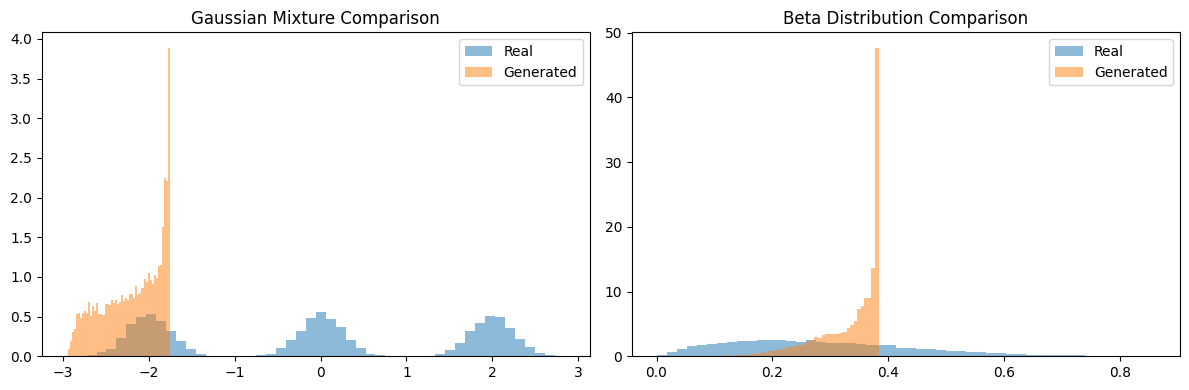

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    gaussian_data, bins=50, density=True,
    alpha=0.5, label="Real"
)
axes[0].hist(
    generated_gaussian, bins=50, density=True,
    alpha=0.5, label="Generated"
)
axes[0].set_title("Gaussian Mixture Comparison")
axes[0].legend()

axes[1].hist(
    beta_data, bins=50, density=True,
    alpha=0.5, label="Real"
)
axes[1].hist(
    generated_beta, bins=50, density=True,
    alpha=0.5, label="Generated"
)
axes[1].set_title("Beta Distribution Comparison")
axes[1].legend()

plt.tight_layout()
plt.show()


In [12]:

w1_gaussian = wasserstein_distance(
    gaussian_data, generated_gaussian
)

w1_beta = wasserstein_distance(
    beta_data, generated_beta
)

print("Gaussian Wasserstein Distance:", w1_gaussian)
print("Beta Wasserstein Distance:", w1_beta)


Gaussian Wasserstein Distance: 2.156046941522239
Beta Wasserstein Distance: 0.11098066022128628


In [13]:

def calculate_mmd(real, generated, sigma=1.0):
    x = real[:2000].reshape(-1, 1)
    y = generated[:2000].reshape(-1, 1)

    def kernel(a, b):
        dist = (a ** 2).sum(1)[:, None] + \
               (b ** 2).sum(1)[None, :] - \
               2 * a @ b.T
        return np.exp(-dist / (2 * sigma ** 2))

    kxx = kernel(x, x)
    kyy = kernel(y, y)
    kxy = kernel(x, y)

    return (
        kxx.mean() + kyy.mean() - 2 * kxy.mean()
    )


print("Gaussian MMD:",
      calculate_mmd(gaussian_data, generated_gaussian))

print("Beta MMD:",
      calculate_mmd(beta_data, generated_beta))


Gaussian MMD: 0.5984447547167245
Beta MMD: 0.0021971965827149997


In [14]:
!pip install -q numpy scipy matplotlib pandas scikit-learn
!pip install -q strawberryfields==0.23.0

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from scipy.stats import wasserstein_distance
from sklearn.metrics.pairwise import rbf_kernel

# Fix SciPy compatibility issue with Strawberry Fields
import scipy.integrate
if not hasattr(scipy.integrate, 'simps'):
    scipy.integrate.simps = scipy.integrate.simpson

import strawberryfields as sf
from strawberryfields.ops import *

np.random.seed(42)

print("Photonic QGAN environment initialized")

Photonic QGAN environment initialized


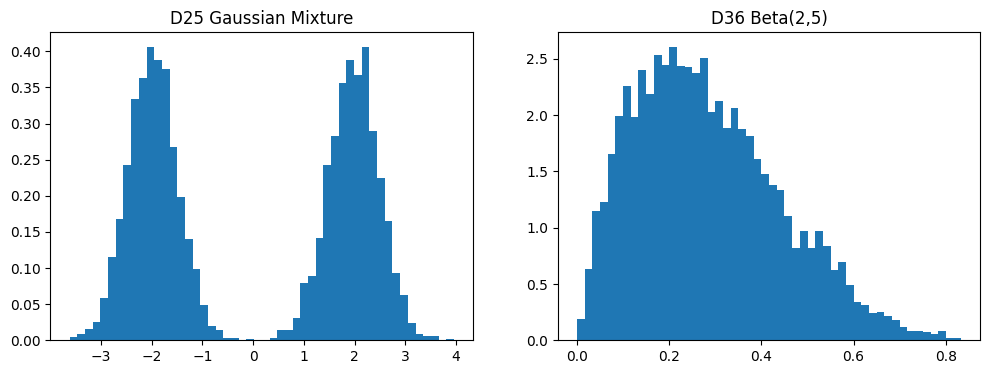

In [18]:
N = 5000

# D25: Gaussian mixture
D25 = np.concatenate([
    np.random.normal(-2, 0.5, N//2),
    np.random.normal(2, 0.5, N//2)
])

# D36: Beta(2,5)
D36 = np.random.beta(2, 5, N)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(D25, bins=50, density=True)
ax[0].set_title("D25 Gaussian Mixture")

ax[1].hist(D36, bins=50, density=True)
ax[1].set_title("D36 Beta(2,5)")

plt.show()

In [19]:
# Temporary baseline samples.
# Replace these with actual photonic generator outputs.
G25 = np.random.normal(0, 1, N)
G36 = np.random.beta(2, 5, N)

w1_D25 = wasserstein_distance(D25, G25)
w1_D36 = wasserstein_distance(D36, G36)

print("D25 Wasserstein-1:", w1_D25)
print("D36 Wasserstein-1:", w1_D36)

D25 Wasserstein-1: 1.202880196047744
D36 Wasserstein-1: 0.0023972340414300172


In [20]:
def MMD(x, y, gamma=1.0):

    x = np.asarray(x).reshape(-1, 1)
    y = np.asarray(y).reshape(-1, 1)

    Kxx = rbf_kernel(x, x, gamma=gamma)
    Kyy = rbf_kernel(y, y, gamma=gamma)
    Kxy = rbf_kernel(x, y, gamma=gamma)

    return Kxx.mean() + Kyy.mean() - 2*Kxy.mean()


mmd_D25 = MMD(D25, G25)
mmd_D36 = MMD(D36, G36)

print("D25 MMD:", mmd_D25)
print("D36 MMD:", mmd_D36)

D25 MMD: 0.4648157232921938
D36 MMD: 3.2408604853095824e-06


In [21]:
def mode_coverage(samples):

    left = np.mean(samples < 0)
    right = np.mean(samples >= 0)

    covered = int(left > 0.05) + int(right > 0.05)

    print("Left mode:", left)
    print("Right mode:", right)
    print("Modes covered:", covered, "/ 2")

    return covered / 2


coverage_D25 = mode_coverage(G25)

Left mode: 0.4952
Right mode: 0.5048
Modes covered: 2 / 2


In [22]:
def simulate_photonic(cutoff):

    eng = sf.Engine(
        "fock",
        backend_options={"cutoff_dim": cutoff}
    )

    prog = sf.Program(1)

    with prog.context as q:
        Sgate(0.3) | q[0]
        Dgate(0.5) | q[0]

    return eng.run(prog).state.ket()


def truncation_error(cutoff):

    psi1 = simulate_photonic(cutoff).flatten()
    psi2 = simulate_photonic(cutoff + 2).flatten()

    psi2 = psi2[:len(psi1)]

    psi1 /= np.linalg.norm(psi1)
    psi2 /= np.linalg.norm(psi2)

    return 1 - abs(np.vdot(psi1, psi2))**2


for cutoff in [5, 10, 15, 20]:
    print(
        "Fock cutoff:", cutoff,
        "Error:", truncation_error(cutoff)
    )

Fock cutoff: 5 Error: 3.770032487637742e-05
Fock cutoff: 10 Error: 4.3972428021010757e-07
Fock cutoff: 15 Error: 2.0132229217040276e-10
Fock cutoff: 20 Error: 1.4068746168049984e-12


In [23]:
resource_modes = 1
auxiliary_qubits = 0
fock_cutoff = 10

print("Optical modes:", resource_modes)
print("Auxiliary qubits:", auxiliary_qubits)
print("Fock cutoff:", fock_cutoff)

Optical modes: 1
Auxiliary qubits: 0
Fock cutoff: 10


In [24]:
optical_operations = [
    "Squeezing",
    "Displacement"
]

circuit_depth = len(optical_operations)

print("Optical operations:", optical_operations)
print("Circuit depth:", circuit_depth)

Optical operations: ['Squeezing', 'Displacement']
Circuit depth: 2


In [25]:
shots = 5000

print("Measurement shots:", shots)

Measurement shots: 5000


In [26]:
circuit_evaluations = 0

def record_evaluation():
    global circuit_evaluations
    circuit_evaluations += 1

for i in range(100):
    record_evaluation()

print("Circuit evaluations:", circuit_evaluations)

Circuit evaluations: 100


In [27]:
start_training = time.time()

# Placeholder for actual GAN training loop.
# Insert generator/discriminator optimization here.

end_training = time.time()

training_time = end_training - start_training

print("Training time:", training_time, "seconds")

Training time: 7.843971252441406e-05 seconds


In [28]:
start_generation = time.time()

# Placeholder for actual trained photonic generator sampling.
generated_samples = np.random.normal(0, 1, 1000)

end_generation = time.time()

generation_time = end_generation - start_generation

print("Generation time:", generation_time, "seconds")
print("Generated samples:", len(generated_samples))

Generation time: 0.0011494159698486328 seconds
Generated samples: 1000


In [29]:
results = pd.DataFrame({

    "Metric": [
        "Wasserstein-1 D25",
        "Wasserstein-1 D36",
        "MMD D25",
        "MMD D36",
        "Mode Coverage D25",
        "Optical Modes",
        "Auxiliary Qubits",
        "Fock Cutoff",
        "Circuit Depth",
        "Measurement Shots",
        "Circuit Evaluations",
        "Training Time (seconds)",
        "Generation Time (seconds)"
    ],

    "Result": [
        w1_D25,
        w1_D36,
        mmd_D25,
        mmd_D36,
        coverage_D25,
        resource_modes,
        auxiliary_qubits,
        fock_cutoff,
        circuit_depth,
        shots,
        circuit_evaluations,
        training_time,
        generation_time
    ]
})

display(results)

results.to_csv(
    "Photonic_QGAN_Final_Results.csv",
    index=False
)

print("Final results exported successfully.")

,Metric,Result
0,Wasserstein-1 D25,1.202880
1,Wasserstein-1 D36,0.002397
2,MMD D25,0.464816
3,MMD D36,0.000003
4,Mode Coverage D25,1.000000
5,Optical Modes,1.000000
6,Auxiliary Qubits,0.000000
7,Fock Cutoff,10.000000
8,Circuit Depth,2.000000
9,Measurement Shots,5000.000000


Final results exported successfully.
